# 6. Results and comparison

Notebook 3 built the cost model on synthetic scores. Notebook 4 produced real ones
for MetroPT. This notebook puts the real scores through exactly the same functions
from `util/evaluation.py` and answers three questions:

1. Which threshold costs least, and what does it catch and miss?
2. How much warning does it give before each failure?
3. Does the choice survive a different cost ratio? On synthetic data it did not move
   at all between 1 : 7 and 1 : 100.

Then the same for Kelmarsh, and the comparison between the two.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from util.evaluation import alarms, evaluate

FIGURES = Path('../figures')
RESULTS = Path('../results')

COST_FALSE_ALARM = 1
COST_MISSED = 20

## MetroPT: the scores

One score per 10-minute row, from the KDE in notebook 4. Higher means less like
February and March.

In [2]:
scores = pd.read_csv(RESULTS / 'metropt_scores.csv', index_col='timestamp', parse_dates=True)['score']

print(f'{len(scores):,} rows from {scores.index.min()} to {scores.index.max()}')
scores.describe(percentiles=[0.5, 0.9, 0.99]).round(1)

25,521 rows from 2020-02-01 00:00:00 to 2020-09-01 03:50:00


count    25521.0
mean        11.0
std         30.9
min          3.7
50%          5.2
90%          7.1
99%        193.4
max        350.0
Name: score, dtype: float64

### The series has holes. Does that matter?

Notebook 4 dropped every row with a sensor gap, so the rows are not evenly spaced.
`alarms()` and `evaluate()` only compare timestamps (is this alarm within 6 hours of
the last one, does it fall inside a failure's window), never row numbers, so the
holes do not break anything. What they *can* do is hide a failure: if the sensors
were off during it, there is nothing to score. So we count the gaps, and below we
check how many rows each failure actually has.

In [3]:
step = scores.index.to_series().diff()
print(f'rows 10 minutes apart: {(step == pd.Timedelta("10min")).mean():.1%}')
print(f'gaps longer than 6 hours: {(step > pd.Timedelta("6h")).sum()}, longest {step.max()}')

rows 10 minutes apart: 99.2%
gaps longer than 6 hours: 29, longest 2 days 00:00:00


## MetroPT: the failures

Dates from the dataset documentation. **The end has to be written as 23:50**, the
last 10-minute row of the day. Notebooks 1 and 4 write `('2020-04-18', '2020-04-18')`,
which is fine for slicing (pandas then takes the whole day), but `evaluate()` turns
it into a single `Timestamp` and the end becomes midnight, so F1 would last zero
minutes.

In [4]:
FAILURES = [
    ('2020-04-18', '2020-04-18 23:50'),   # F1
    ('2020-05-29', '2020-05-30 23:50'),   # F2
    ('2020-06-05', '2020-06-07 23:50'),   # F3
    ('2020-07-15', '2020-07-15 23:50'),   # F4
]
NAMES = ['F1', 'F2', 'F3', 'F4']

rows = []
for name, (start, end) in zip(NAMES, FAILURES):
    inside = scores[start:end]
    before = scores[pd.Timestamp(start) - pd.Timedelta('2D'):pd.Timestamp(start) - pd.Timedelta('10min')]
    possible = (pd.Timestamp(end) - pd.Timestamp(start)) / pd.Timedelta('10min') + 1
    rows.append({'failure': name, 'rows': len(inside), 'possible rows': int(possible),
                 'median score inside': inside.median(), 'max inside': inside.max(),
                 'max in 2 days before': before.max()})

pd.DataFrame(rows).set_index('failure').round(1)

,rows,possible rows,median score inside,max inside,max in 2 days before
failure,,,,,
F1,144,144,144.5,162.5,44.3
F2,270,288,5.5,177.4,9.8
F3,348,432,191.0,234.7,115.1
F4,144,144,8.3,49.2,61.4


F2 and F3 lose some rows to gaps but keep most of them, so none of the four is
hidden. F2's median is at normal level: the leak shows for only part of its two-day
label, as notebook 4 found. F4 never gets above 50 inside its own window; its highest
score is in the two days before.

## Evaluate from April only

The KDE was fitted on February and March, so it has seen those rows. Scoring them
counts in its favour, so we leave them out and evaluate from 1 April. This removes
exactly one false alarm, so it changes nothing, but it is the honest way to report it.

In [5]:
test = scores['2020-04-01':]
test_days = (test.index.max() - test.index.min()) / pd.Timedelta('1D')
print(f'evaluation period: {test.index.min().date()} to {test.index.max().date()}, {test_days:.0f} days')

evaluation period: 2020-04-01 to 2020-09-01, 153 days


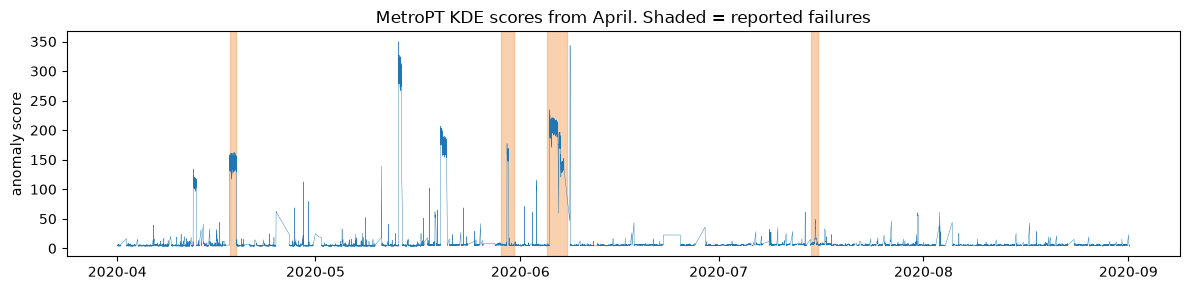

In [6]:
def mark_failures(ax, failures):
    for start, end in failures:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='sandybrown', alpha=0.5)


fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(test.index, test, lw=0.3, color='tab:blue')
mark_failures(ax, FAILURES)
ax.set_ylabel('anomaly score')
ax.set_title('MetroPT KDE scores from April. Shaded = reported failures')
plt.tight_layout()

Every failure is visible, but so are several excursions just as tall where nothing
was reported. That is the problem the cost model has to settle.

## MetroPT: cost against threshold

Same sweep as notebook 3, on a grid of whole numbers from 5 to 350 (the range of the
scores). False alarm = 1, missed failure = 20.

In [7]:
thresholds = np.arange(5, 351, 1.0)
sweep = pd.DataFrame([evaluate(test, FAILURES, t) for t in thresholds], index=thresholds)
sweep['cost'] = sweep['false_alarms'] * COST_FALSE_ALARM + sweep['missed'] * COST_MISSED

# Ties go to the lowest threshold: it alarms earlier.
best = sweep.index[sweep['cost'] == sweep['cost'].min()].min()
sweep.loc[best, ['detected', 'missed', 'false_alarms', 'cost']]

detected         4
missed           0
false_alarms    22
cost            22
Name: 61.0, dtype: int64

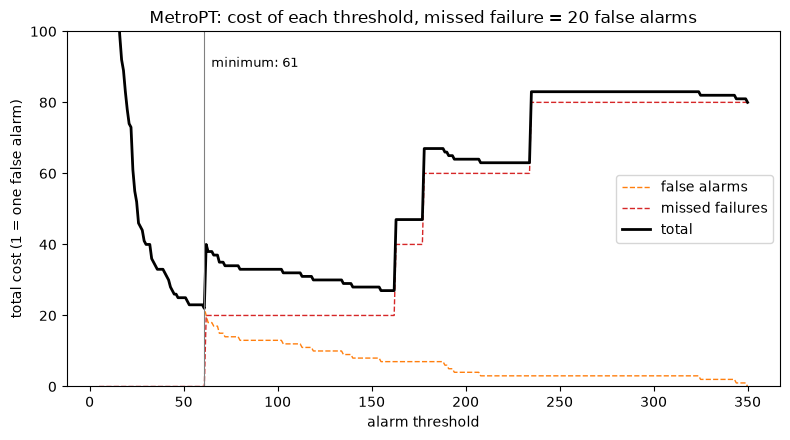

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep.index, sweep['false_alarms'] * COST_FALSE_ALARM,
        color='tab:orange', lw=1, ls='--', label='false alarms')
ax.plot(sweep.index, sweep['missed'] * COST_MISSED,
        color='tab:red', lw=1, ls='--', label='missed failures')
ax.plot(sweep.index, sweep['cost'], color='black', lw=2, label='total')
ax.axvline(best, color='grey', lw=0.8)
ax.annotate(f'minimum: {best:.0f}', (best, 90), xytext=(5, 0), textcoords='offset points', fontsize=9)

ax.set_ylim(0, 100)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('total cost (1 = one false alarm)')
ax.set_title(f'MetroPT: cost of each threshold, missed failure = {COST_MISSED} false alarms')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_cost_vs_threshold.png', dpi=200)

The curve does not have one clear bottom. It has two shelves: one around 60 where
all four failures are caught, and one from about 135 to 160 where F4 is given up
and the false alarms drop to single figures. Zoomed in:

In [9]:
sweep.loc[[40, 50, 55, 60, 61, 62, 70, 100, 130, 150, 155, 160, 165],
          ['detected', 'false_alarms', 'cost']].T

,40.0,50.0,55.0,60.0,61.0,62.0,70.0,100.0,130.0,150.0,155.0,160.0,165.0
detected,4,4,4,4,4,3,3,3,3,3,3,3,2
false_alarms,32,25,23,23,22,20,15,13,10,8,7,7,7
cost,32,25,23,23,22,40,35,33,30,28,27,27,47


Two things stand out.

**The minimum is a knife-edge.** At 61 all four failures are caught; at 62, F4 is
lost and cost jumps by 20. This is the lopsided shape notebook 3 warned about, and
the reason the rule in `DECISIONS.md` is to sit at or a little below the minimum.

**The two shelves are only a few units apart.** Catching F4 costs about 15 extra
false alarms, against the 20 a miss is worth. As predicted from notebook 4: a shallow
minimum.

## MetroPT: what the chosen threshold does

In [10]:
result = evaluate(test, FAILURES, best)

print(f'threshold {best:.0f}')
print(f'detected {result["detected"]} of {len(FAILURES)}, missed {result["missed"]}')
print(f'false alarms {result["false_alarms"]} in {test_days:.0f} days, '
      f'one every {test_days / result["false_alarms"]:.1f} days')

lead_hours = (result['lead_times'].dt.total_seconds() / 3600).round(1)
lead_hours.index = NAMES
lead_hours.rename('hours of warning (negative = after it started)')

threshold 61
detected 4 of 4, missed 0
false alarms 22 in 153 days, one every 7.0 days


F1    -0.3
F2   -23.3
F3    37.8
F4    21.7
Name: hours of warning (negative = after it started), dtype: float64

Only F3 gets real warning, a day and a half. F1 is caught 20 minutes after it
starts, F2 almost a day into its two-day window.

### Is F4 really detected?

F4 is caught by one alarm about 22 hours before the reported date. Nothing inside
F4's own window crosses the threshold. With a false alarm every week or so, how
likely is it that one lands in F4's window by pure chance? The window is the 2 days
of `lead` plus the day of the failure.

In [11]:
false_per_day = result['false_alarms'] / test_days
window_days = 2 + 1
print(f'false alarms expected in a random 3-day window: {false_per_day * window_days:.2f}')

false alarms expected in a random 3-day window: 0.43


Roughly two chances in five. So the "detection" of F4 at threshold 61 is
indistinguishable from luck, and the notebook 1 finding stands: there is no visible
F4 signature. Honestly reported, the detector catches **three of four** failures,
and the cheapest threshold catches the fourth by chance.

### Where do the false alarms happen?

April      7
May       11
June       3
August     1
Name: count, dtype: int64

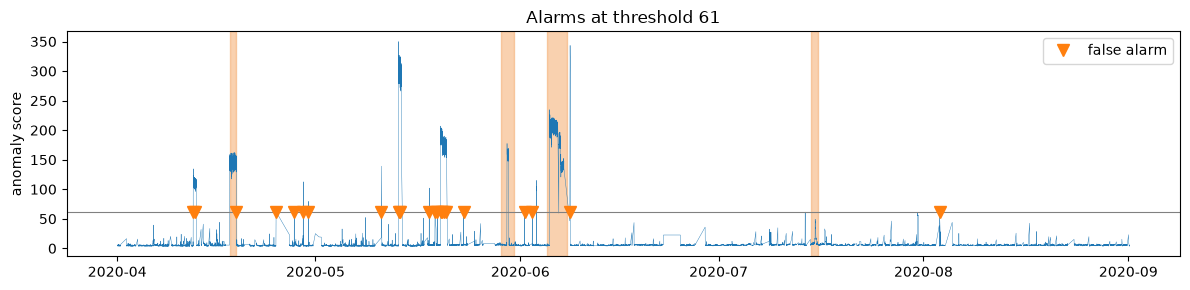

In [12]:
false_alarm_times = [t for t in result['alarms']
                     if not any(pd.Timestamp(s) - pd.Timedelta('2D') <= t <= pd.Timestamp(e)
                                for s, e in FAILURES)]

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(test.index, test, lw=0.3, color='tab:blue')
mark_failures(ax, FAILURES)
ax.axhline(best, color='grey', lw=0.8)
ax.plot(false_alarm_times, [best] * len(false_alarm_times), 'v', color='tab:orange',
        markersize=8, label='false alarm')
ax.set_ylabel('anomaly score')
ax.set_title(f'Alarms at threshold {best:.0f}')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_false_alarms.png', dpi=200)

pd.Series(pd.DatetimeIndex(false_alarm_times).month_name()).value_counts(sort=False)

Almost all of them fall between April and June, and only one after F4. Half come
from one stretch, 13–23 May, which includes the highest score in the whole series
(350). That is the unreported mid-May excursion from the open questions in
`DECISIONS.md`. Most of the rest come in the days just after F1, F2 and F3 end,
when the score has not yet settled. Whether those are false or a leak that was not
fully fixed, we cannot tell from the labels. So 22 is an upper bound on what a
technician would really have found nothing on.

## MetroPT: lead time against threshold

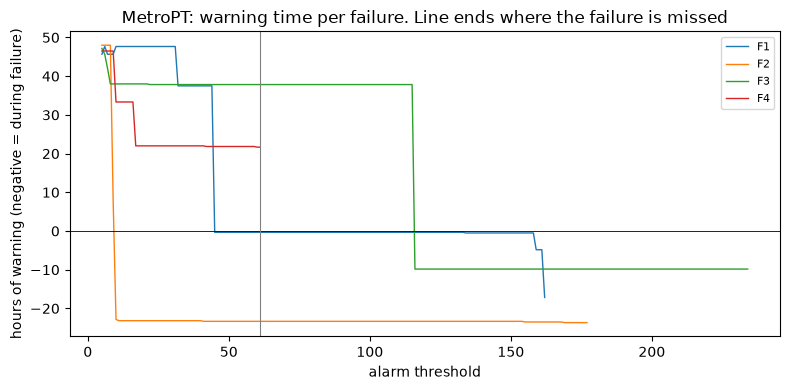

In [13]:
hours = pd.DataFrame([lt.dt.total_seconds() / 3600 for lt in sweep['lead_times']], index=sweep.index)
hours.columns = NAMES

fig, ax = plt.subplots(figsize=(8, 4))
for name in NAMES:
    ax.plot(hours.index, hours[name], lw=1, label=name)
ax.axhline(0, color='black', lw=0.6)
ax.axvline(best, color='grey', lw=0.8)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('hours of warning (negative = during failure)')
ax.set_title('MetroPT: warning time per failure. Line ends where the failure is missed')
ax.legend(fontsize=8)
plt.tight_layout()

**F3's warning comes from one alarm.** On 3 June, a day and a half before F3, the
score reaches 115. Any threshold up to 115 catches it; at 116 that warning is gone
and F3 is only seen 10 hours after it starts. F1 gets a similar warning only below
about 44, which costs 30+ false alarms. F2 is always caught almost a day into its
window. So above 115, the detector gives **no early warning on any failure**: it
only confirms leaks that are already under way.

## MetroPT: does the threshold move with the cost ratio?

On synthetic data the chosen threshold stayed put from 1 : 7 to 1 : 100. Here:

,threshold,detected,false alarms
missed costs,,,
5,155.0,3,7
20,61.0,4,22
100,61.0,4,22


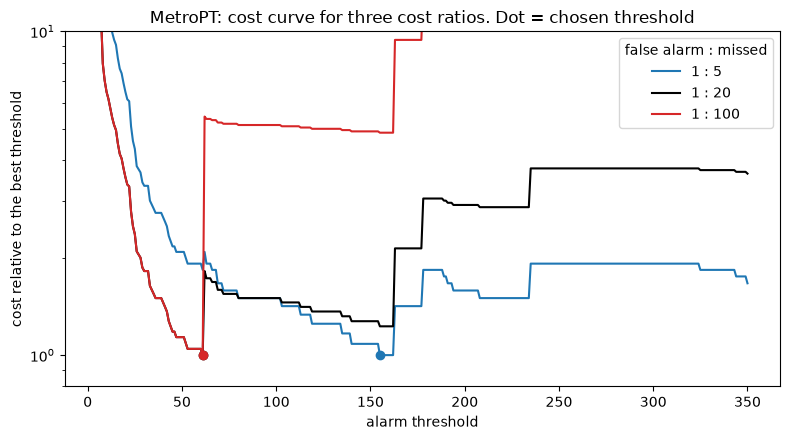

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))

rows = []
for ratio, colour in [(5, 'tab:blue'), (20, 'black'), (100, 'tab:red')]:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen = cost.index[cost == cost.min()].min()
    ax.plot(cost.index, cost / cost.min(), color=colour, lw=1.5, label=f'1 : {ratio}')
    ax.plot(chosen, 1, 'o', color=colour)
    r = sweep.loc[chosen]
    rows.append({'missed costs': ratio, 'threshold': chosen,
                 'detected': r['detected'], 'false alarms': r['false_alarms']})

ax.set_ylim(0.8, 10)
ax.set_yscale('log')
ax.set_xlabel('alarm threshold')
ax.set_ylabel('cost relative to the best threshold')
ax.set_title('MetroPT: cost curve for three cost ratios. Dot = chosen threshold')
ax.legend(title='false alarm : missed')
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_cost_ratio_sensitivity.png', dpi=200)

pd.DataFrame(rows).set_index('missed costs')

1     350.0
3     155.0
15     61.0
dtype: float64

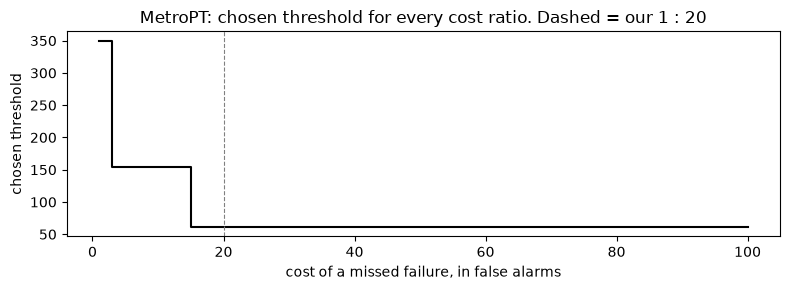

In [15]:
ratios = np.arange(1, 101)
chosen = []
for ratio in ratios:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen.append(cost.index[cost == cost.min()].min())
chosen = pd.Series(chosen, index=ratios)

fig, ax = plt.subplots(figsize=(8, 3))
ax.step(ratios, chosen, where='post', color='black')
ax.axvline(COST_MISSED, color='grey', lw=0.8, ls='--')
ax.set_xlabel('cost of a missed failure, in false alarms')
ax.set_ylabel('chosen threshold')
ax.set_title('MetroPT: chosen threshold for every cost ratio. Dashed = our 1 : 20')
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_threshold_vs_ratio.png', dpi=200)

# The ratios at which the choice changes
chosen[chosen.diff() != 0]

**The synthetic result does not hold.** The choice is still a step function with
only a few steps, but the step that matters now sits at about 1 : 15, just below our
1 : 20. Under 15 the cheapest threshold is about 155 (three failures, 7 false
alarms); above it, about 61 (four failures, 22 false alarms). A small change in a
cost we guessed flips the decision.

The step is about F4 only, and F4 is the failure we just saw is caught by luck.
Setting F4 aside, the cost model picks the shelf at 155, but there the detector
gives no warning on anything. Our rule from notebook 3 is to err low, because a
lower threshold warns earlier. Erring low to **110**, a little under F3's 115
precursor, keeps the day and a half of warning on F3 for 5 more false alarms.

In [16]:
CHOSEN = 110

rows = []
for t in [best, CHOSEN, 155]:
    r = evaluate(test, FAILURES, t)
    row = {'threshold': t, 'detected': r['detected'], 'false alarms': r['false_alarms'],
           'cost at 1 : 20': r['false_alarms'] + r['missed'] * COST_MISSED}
    for name, lt in zip(NAMES, r['lead_times']):
        row[f'{name} warning (h)'] = round(lt.total_seconds() / 3600, 1)
    rows.append(row)

pd.DataFrame(rows).set_index('threshold')

,detected,false alarms,cost at 1 : 20,F1 warning (h),F2 warning (h),F3 warning (h),F4 warning (h)
threshold,,,,,,,
61.0,4,22,22,-0.3,-23.3,37.8,21.7
110.0,3,12,32,-0.3,-23.3,37.8,NaN
155.0,3,7,27,-0.5,-23.5,-9.8,NaN


## MetroPT: summary

| threshold | 61 (cost minimum at 1 : 20) | 110 (our choice) | 155 (cheapest without F4) |
|---|---|---|---|
| detected | 4 of 4, F4 probably by chance | 3 of 4 | 3 of 4 |
| false alarms, Apr–Sep (153 days) | 22 | 12 | 7 |
| cost at 1 : 20 | 22 | 32 | 27 |
| warning before F3 | 1.5 days | 1.5 days | none (10 h late) |
| F1, F2 | caught after they started | same | same |

The method works on MetroPT for the failures that leave a mark in the sensors
(F1–F3), and gives real early warning for one of them. The price is a false alarm
every one to three weeks. The cost model on its own does not see that the cheapest
point gives no warning: lead time has to be read next to the cost curve.

## Kelmarsh

**Waiting for `results/kelmarsh_scores.csv` from Christian.** When it arrives, this
section runs the same four steps: sweep, report at the minimum, lead time, ratio
sensitivity. The failure list is the merged forced outages from notebook 2 for the
turbine the scores belong to.

What we expect, and what would show it:

- Most forced outages are protective stops (tower oscillation, rotor overspeed,
  pitch, converter), which happen in a moment. If the hypothesis is right, most
  detections will have lead times near zero or negative, i.e. the score rises
  *because* the turbine stopped, not before.
- With many short outages, the `lead` of 2 days covers a large share of the year, so
  random alarms will often count as detections. The same chance check as for F4
  tells us how much of the recall is real.

## Does the method give the same answer on both datasets?

*To be finished when the Kelmarsh numbers are in.* Our hypothesis is no: MetroPT
has leaks that build up over hours and leave a signature in the sensors first;
Kelmarsh mostly has protective stops that are instantaneous. If the Kelmarsh lead
times are around zero, that is our conclusion.

## When is this technique the right tool?

*Draft, based on MetroPT; to be checked against Kelmarsh.*

Learning normal operation and alarming on deviations is the right tool when:

- **The fault develops before it becomes a failure** and moves the sensors while it
  does. MetroPT F3 is the example: a day and a half of warning. Even there the
  warning rests on a single alarm just under the noise, so it is fragile.
- **The fault shows in the sensors we model.** F4 left no trace in the seven
  compressor sensors, and no threshold finds it except by chance.
- **There is plenty of normal data and few failures.** That is exactly why we
  could not train a classifier on MetroPT.
- **A false alarm is cheap compared with a miss.** Even a sensible threshold here
  produces a false alarm every one to three weeks, because ordinary operation
  regularly scores as high as a leak.

It is the wrong tool when the failure is a sudden event (a protective trip, a
broken part with no wear before it): there is nothing to warn about before it
happens, and the detector merely confirms after the fact what the turbine's own
control system already knew. It is also the wrong tool when nobody can put a
rough price on a false alarm against a miss, because, as the sensitivity plot
shows, the choice of threshold depends on it.